# Day 3: Time-based split
## Subtask 3.1: Reload, remove duplicates, check the data
1. **Question:** is the reloaded 12-week data correct (dtypes, dates) and free of same-day duplicates?
2. **Proof:** an assertion cell that passes.
3. **Silent risks:** dtypes changing after reload, wrong columns in the duplicate rule (adding price would quietly keep duplicates), dates shifted by a day.
4. **Expected:** 3,386,963 rows before; 3,386,963 - 301,088 = **3,085,875** after; first date 2020-07-01 (Wednesday), last date 2020-09-22 (Tuesday).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:

transactions = pd.read_parquet('../data/processed/transactions_12w.parquet')

print('Shape:', transactions.shape)
display(transactions.head())
print(transactions.dtypes)

Shape: (3386963, 5)


,t_dat,customer_join_idx,article_id,price,sales_channel_id
0,2020-07-01,38,825577003,0.013542,2
1,2020-07-01,38,849487005,0.042356,2
2,2020-07-01,38,772659001,0.023712,2
3,2020-07-01,38,804732004,0.042356,2
4,2020-07-01,38,804732004,0.042356,2


t_dat                datetime64[us]
customer_join_idx             int32
article_id                    int32
price                       float32
sales_channel_id               int8
dtype: object


In [3]:
# A duplicate = same day + same customer + same article (price and channel NOT included)
duplicate_columns = ['t_dat', 'customer_join_idx', 'article_id']

rows_before = len(transactions)
clean = transactions.drop_duplicates(subset=duplicate_columns, keep='first')
rows_after = len(clean)

print('Rows before: ', rows_before)
print('Rows after:  ', rows_after)
print('Rows removed:', rows_before - rows_after)

Rows before:  3386963
Rows after:   3085875
Rows removed: 301088


**Duplicate rule = (t_dat, customer, article). Price and channel are NOT included.**
The signal is "this customer chose this article on this day". Buying it twice at two prices (e.g. a mid-day markdown) or via two channels is still one choice, not two.

In [4]:
# 1. Dtypes first: the date checks below only make sense if t_dat really is a date
assert pd.api.types.is_datetime64_any_dtype(clean['t_dat']), 't_dat should be a datetime'
assert clean['customer_join_idx'].dtype == 'int32', 'customer_join_idx should be int32'
assert clean['article_id'].dtype == 'int32', 'article_id should be int32'

# 2. Row count: Day 1 rows (3,386,963) minus Day 2 duplicates (301,088)
assert rows_after == 3_085_875, f'expected 3,085,875 rows after dedup, got {rows_after:,}'

# 3. Dates: window is 2020-07-01 (Wednesday) to 2020-09-22 (Tuesday)
first_date = clean['t_dat'].min()
last_date = clean['t_dat'].max()
assert first_date == pd.Timestamp('2020-07-01'), f'expected first date 2020-07-01, got {first_date.date()}'
assert last_date == pd.Timestamp('2020-09-22'), f'expected last date 2020-09-22, got {last_date.date()}'
assert first_date.day_name() == 'Wednesday', f'first date should be a Wednesday, got {first_date.day_name()}'
assert last_date.day_name() == 'Tuesday', f'last date should be a Tuesday, got {last_date.day_name()}'

# 4. No missing values in the key columns
assert clean[duplicate_columns].isna().sum().sum() == 0, 'key columns should have no missing values'

# 5. Dedup really worked
assert not clean.duplicated(subset=duplicate_columns).any(), 'there should be no same-day duplicates left'

print('All validation checks passed.')

All validation checks passed.


**Why is dropping same-day duplicates safe before the split, but article popularity is not?**
Dropping duplicates is row-local: each row's fate depends only on rows with the same customer, article and date, so nothing from future weeks leaks into training. Popularity is a statistic counted over many rows, so computing it before the split would count validation and test purchases, which is leakage.

## Subtask 3.2: Weekly purchase chart
1. **Question:** do the validation and test weeks look like the training weeks?
2. **Proof:** weekly table + chart, plus two passing assertions (totals add up, 7 dates per week).
3. **Silent risks:** pandas' default week ends on Sunday and would mix two of my weeks; a missing day makes a week look quiet; rows lost while grouping.
4. **Expected:** average weekly purchases = 3,085,875 / 12 = about **257,000**.

In [5]:
avg_weekly_purcashes = rows_after / 12
print(f'Average weekly purchases: {avg_weekly_purcashes:,.0f}')

Average weekly purchases: 257,156


In [6]:
transactions['week'] = pd.to_datetime(transactions['t_dat'])
win_start = transactions['week'].min()

transactions['week'] = (transactions['week'] - win_start).dt.days // 7 

print(transactions['week'].value_counts().sort_index())

week
0     337419
1     286672
2     289528
3     299469
4     319469
5     289161
6     265211
7     256644
8     283181
9     264657
10    255241
11    240311
Name: count, dtype: int64


In [7]:
# Step 1: give every row a week number 0..11
# week = how many whole weeks (7 days) since the first date
start_date = clean['t_dat'].min()

days_since_start = (clean['t_dat'] - start_date).dt.days
clean['week'] = days_since_start // 7

print(clean['week'].min(), 'to', clean['week'].max())   # expect 0 to 11

0 to 11


In [8]:
# Step 2: count three things per week
weekly = clean.groupby('week').agg(
    start_date=('t_dat', 'min'),
    purchases=('article_id', 'size'),
    active_customers=('customer_join_idx', 'nunique'),
    active_articles=('article_id', 'nunique'),
)

# Optional: new articles = articles whose FIRST sale in the window is in this week
first_week_of_article = clean.groupby('article_id')['week'].min()
weekly['new_articles'] = first_week_of_article.value_counts()

weekly

,start_date,purchases,active_customers,active_articles,new_articles
week,,,,,
0,2020-07-01,308779,85648,21503,21503
1,2020-07-08,262606,75996,20598,3860
2,2020-07-15,265141,77277,20553,2587
3,2020-07-22,275088,80591,21204,2198
4,2020-07-29,291354,82802,20646,1632
5,2020-08-05,262544,74833,19482,1288
6,2020-08-12,240262,71094,19446,1295
7,2020-08-19,233455,72035,19976,1519
8,2020-08-26,258029,80253,19614,1314


In [9]:
# Step 3: conservation checks
# Check 1: weekly purchases must add up to all rows
total_weekly = weekly['purchases'].sum()
assert total_weekly == len(clean), f'expected {len(clean):,} purchases in total, got {total_weekly:,}'

# Check 2: every week must have exactly 7 different dates (no missing days)
dates_per_week = clean.groupby('week')['t_dat'].nunique()
assert (dates_per_week == 7).all(), f'every week should have 7 dates, got {dates_per_week.tolist()}'

print('Average weekly purchases:', round(weekly['purchases'].mean()))
print('Conservation checks passed.')

Average weekly purchases: 257156
Conservation checks passed.


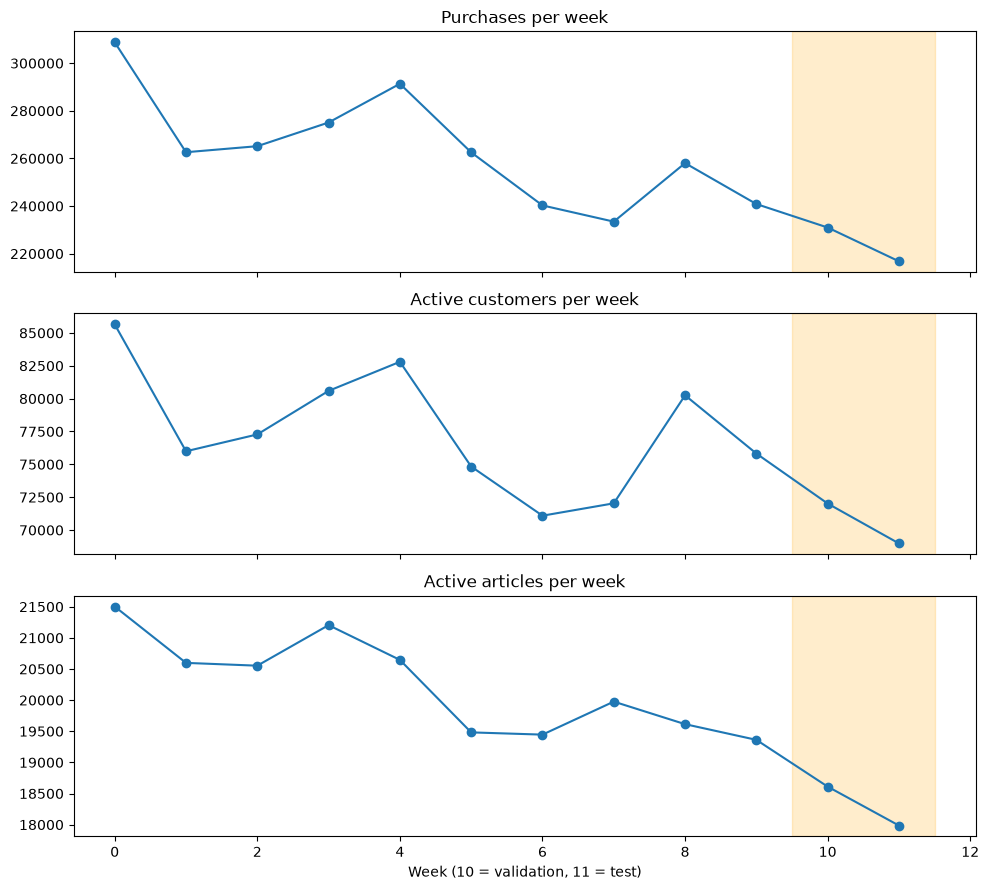

In [10]:
# Step 4: three charts stacked, validation and test weeks shaded
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(weekly.index, weekly['purchases'], marker='o')
axes[0].set_title('Purchases per week')

axes[1].plot(weekly.index, weekly['active_customers'], marker='o')
axes[1].set_title('Active customers per week')

axes[2].plot(weekly.index, weekly['active_articles'], marker='o')
axes[2].set_title('Active articles per week')
axes[2].set_xlabel('Week (10 = validation, 11 = test)')

# shade weeks 10 and 11 on all three charts
for ax in axes:
    ax.axvspan(9.5, 11.5, alpha=0.2, color='orange')

plt.tight_layout()
plt.savefig(r'C:/Users/srisu/AppData/Local/Temp/claude/5f3aba0acd41fd42/ed8e8adb-1872-4f2c-9715-dac9ee828a10/scratchpad/weekly.png')
plt.show()

**What the chart shows**
1. **Weeks 10 and 11** are the quietest, but they continue a gentle downward trend rather than jumping. Week 10 is close to week 7 (231k vs 233k); week 11 is about 7% lower. Slightly low, not unusual.
2. **No spike in week 9** (241k, a normal week). The biggest week is week 0 (309k), probably the tail of the late-June clearance sale.
3. **Active articles drift down** from 21.5k to 18k, and new articles per week fall from ~3,900 to 944, so the catalogue is turning over (matters for cold-start).

**If the test week were a big sale week, which baseline benefits most?** The popularity baseline, because in a sale everyone buys the same few discounted bestsellers, so recommending the most-bought items matches far more purchases than usual.

## Subtask 3.3: Split into train / validation / test
**Predictions (from the weekly table):**
- Train (weeks 0-9) = 3,085,875 - 230,980 - 216,792 = **2,638,103**
- Validation (week 10) = **230,980**
- Test (week 11) = **216,792**

In [11]:
# Step 1: train = weeks 0 to 9 (the past)
train = clean[clean['week'] <= 9].copy()
print('Train rows:', len(train))

Train rows: 2638103


In [12]:
# Step 2: validation = week 10, test = week 11
val = clean[clean['week'] == 10].copy()
test = clean[clean['week'] == 11].copy()

print('Validation rows:', len(val))
print('Test rows:      ', len(test))

Validation rows: 230980
Test rows:       216792


In [13]:
# Step 3: every row must land in exactly one table
total = len(train) + len(val) + len(test)
assert total == 3_085_875, f'expected 3,085,875 rows across train+val+test, got {total:,}'
print('Split check passed.')

Split check passed.


In [14]:
print('Train:', train['t_dat'].min(), 'to', train['t_dat'].max())
print('Val:  ', val['t_dat'].min(), 'to', val['t_dat'].max())
print('Test: ', test['t_dat'].min(), 'to', test['t_dat'].max())



Train: 2020-07-01 00:00:00 to 2020-09-08 00:00:00
Val:   2020-09-09 00:00:00 to 2020-09-15 00:00:00
Test:  2020-09-16 00:00:00 to 2020-09-22 00:00:00


In [15]:
assert train['t_dat'].max() < val['t_dat'].min(), 'train and val overlap'
assert val['t_dat'].max() < test['t_dat'].min(), 'val and test overlap'
assert train['t_dat'].max() < test['t_dat'].min(), 'train and test overlap'
print('No overlap between train, val, and test.')

No overlap between train, val, and test.


In [21]:
val_answers = val.groupby('customer_join_idx')['article_id'].unique()

In [22]:
print(len(val_answers))
val_answers.head(3)

72019


customer_join_idx
2                [794321007]
6     [719530003, 448509014]
38               [734592001]
Name: article_id, dtype: object

In [23]:
# Step 6a: one answer-key row per active customer in week 10 (from the weekly table)
assert len(val_answers) == 72_019, f'expected 72,019 customers in the answer key, got {len(val_answers):,}'
print('Answer key customer count matches the weekly table.')

Answer key customer count matches the weekly table.


In [24]:
# Step 6b: average articles per customer
# estimate = rows / customers (still counts Monday + Thursday repeats)
estimate = len(val) / len(val_answers)

# real = length of each customer's unique list, then the average
articles_per_customer = val_answers.apply(len)
real_average = articles_per_customer.mean()

print(f'Estimate (rows / customers): {estimate:.2f}')
print(f'Real average (unique articles per customer): {real_average:.2f}')
print('Repeats removed within the week:', len(val) - articles_per_customer.sum())

Estimate (rows / customers): 3.21
Real average (unique articles per customer): 3.16
Repeats removed within the week: 3070


## Answer key decisions
**A repeated article in the same week counts once.** The model recommends an article in one slot, so one recommendation can only be one hit; counting it twice would reward the model for something it didn't do.

**Average:** estimate 230,980 / 72,019 = 3.21; real 3.16. It's lower because the estimate counts rows, while the answer key counts each article once per customer (3,070 within-week repeats removed).

**Interview: what is the correct answer for one customer in the evaluation week, and why a group?**
The correct answer is the set of articles the customer actually bought that week. It's a group, not one label, because people buy several items a week (about 3 here), and the model returns a ranked list, so we score how many recommended items appear in that set. That's also why recall@10 looks low: with about 3 purchases, even a perfect list has at most about 3 hits out of 10.